# Kredi Kartı Dolandırıcılığı Tespiti

Önceki egzersizler, bir sinir ağının tüm farklı bileşenlerine daha yakından bakmanızı sağladı:
* sıralı (sequential) yoğun (Dense) bir Sinir Ağı mimarisi,
* derleme (compilation) yöntemi,
* modelin eğitilmesi (fitting).

Şimdi **çok fazla veri içeren** gerçek hayat bir veri seti üzerinde çalışalım!

**Veri seti: `Kredi Kartı İşlemleri (Credit Card Transactions)`**

Bu açık uçlu challenge’da, **kredi kartı işlemlerinden elde edilmiş verilerle** çalışacaksınız.

Bu veriler **hassas** olduğu için, toplam 31 sütundan yalnızca 3’ü bilinmektedir; geri kalanlar verileri **anonimleştirmek** amacıyla dönüştürülmüştür (aslında bunlar, orijinal verilerin **PCA projeksiyonlarıdır**).

Bilinen 3 sütun şunlardır:

* `TIME`: İşlemin, veri setindeki ilk işleme göre geçen süresi  
* `AMOUNT`: İşlem tutarı  
* `CLASS` (hedef değişkenimiz):
    * `0 : geçerli işlem`
    * `1 : sahte (fraud) işlem`

❓ **Soru** ❓ Veri setini indirerek başlayın:
* Kaggle üzerinden: [buradan](https://www.kaggle.com/mlg-ulb/creditcardfraud)
* veya bizim URL’mizden: [buradan](https://d32aokrjazspmn.cloudfront.net/materials/creditcard.csv)

Veriyi yükleyerek `X` ve `y` değişkenlerini oluşturun.

In [9]:
!pip install imbalanced-learn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [10]:
# Linear Algebra
import pandas as pd
import numpy as np
from collections import Counter

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import confusion_matrix

# Imbalanced Classes
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

# TensorFlow Keras
import keras
from keras import models, layers
from keras.callbacks import EarlyStopping
from keras import regularizers, optimizers
from keras.optimizers.schedules import ExponentialDecay


In [11]:
# SENİN KODUN BURAYA
path = "creditcard.csv"
data = pd.read_csv(path)
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [12]:
X = data.drop(columns='Class')
y = data['Class']

## 1. Sınıfların yeniden dengelenmesi

In [13]:
# Sınıf dengesini kontrol edelim
pd.Series(y).value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

☝️ Bu `fraud detection` (sahtekârlık tespiti) challenge’ında **sınıflar aşırı derecede dengesizdir**:
* %99.8 normal işlemler
* %0.2 sahte (fraud) işlemler

**Ciddi yeniden dengeleme (rebalancing) stratejileri uygulamazsak sahtekârlık vakalarını tespit edemeyiz!**

❓ **Soru** ❓
1. **Önce**, veri setinizden üç ayrı bölme oluşturun: `Train / Val / Test`.  
   Doğrulama (validation) ve test setlerinin **dengesiz** kalması son derece önemlidir; böylece modeli değerlendirirken gerçek koşullar korunur ve veri sızıntısı (data leakage) oluşmaz. Test setinizi bu notebook’un **en son hücresine kadar saklayın**!

&nbsp;

2. **İkinci olarak**, yalnızca eğitim setinizi (training set) yeniden dengeleyin. Birçok seçeneğiniz var:

- Azınlık sınıfını rastgele oversample etmek (düz NumPy fonksiyonlarıyla).  
  *(En iyi seçenek değildir; çünkü satırları kopyalayarak veri sızıntısı yaratır.)*
- <a href="https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/">**`Synthetic Minority Oversampling Technique - SMOTE`**</a> kullanarak, mevcut gözlemleri ağırlıklandırıp yeni veri noktaları üretmek
- Buna ek olarak, çoğunluk sınıfını bir miktar küçültmek için  
  <a href="https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/">**`RandomUnderSampler`**</a> da deneyebilirsiniz

In [14]:
# SENİN KODUN BURAYA
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.3, random_state=42)

In [15]:
print(f"X_train.shape = {X_train.shape}")
print(f"y_train.shape = {y_train.shape}")
print(f"X_val.shape = {X_val.shape}")
print(f"y_val.shape = {y_val.shape}")
print(f"X_test.shape = {X_test.shape}")
print(f"y_test.shape = {y_test.shape}")

X_train.shape = (139554, 30)
y_train.shape = (139554,)
X_val.shape = (59810, 30)
y_val.shape = (59810,)
X_test.shape = (85443, 30)
y_test.shape = (85443,)


In [16]:
print(np.sum(y_train[y_train==1]))
print(np.sum(y_val[y_val==1]))
print(np.sum(y_test[y_test==1]))

print("-"*100)

print(f"Eğitim setinde {pd.Series(y_train).value_counts()[1]} dolandırıcılık işlemi var")
print(f"Doğrulama setinde {pd.Series(y_val).value_counts()[1]} dolandırıcılık işlemi var")
print(f"Test setinde {pd.Series(y_test).value_counts()[1]} dolandırıcılık işlemi var")

258
98
136
----------------------------------------------------------------------------------------------------
Eğitim setinde 258 dolandırıcılık işlemi var
Doğrulama setinde 98 dolandırıcılık işlemi var
Test setinde 136 dolandırıcılık işlemi var


In [17]:
# Örnekleme stratejileri
over = SMOTE(sampling_strategy=0.1)
under = RandomUnderSampler(sampling_strategy=0.33, random_state=42)

In [20]:
from sklearn import set_config; set_config(display='diagram')

line = [('o', over), ('u', under)]
pipeline = Pipeline(steps=line)
pipeline

Pipeline(steps=[('o', SMOTE(sampling_strategy=0.1)),
                ('u',
                 RandomUnderSampler(random_state=42, sampling_strategy=0.33))])

In [31]:
X_train_res, y_train_res = pipeline.fit_resample(X=X_train, y=y_train)
print(f"X_train_resampled.shape = {X_train_res.shape}")
print(f"y_train_resampled.shape = {y_train_res.shape}")

X_train_resampled.shape = (56138, 30)
y_train_resampled.shape = (56138,)


In [34]:
stacked_resampled_data = np.hstack([X_train_res, y_train_res.values.reshape(-1,1)])
np.random.shuffle(stacked_resampled_data)

X_train_res = stacked_resampled_data[:,:30]
y_train_res = stacked_resampled_data[:,-1]


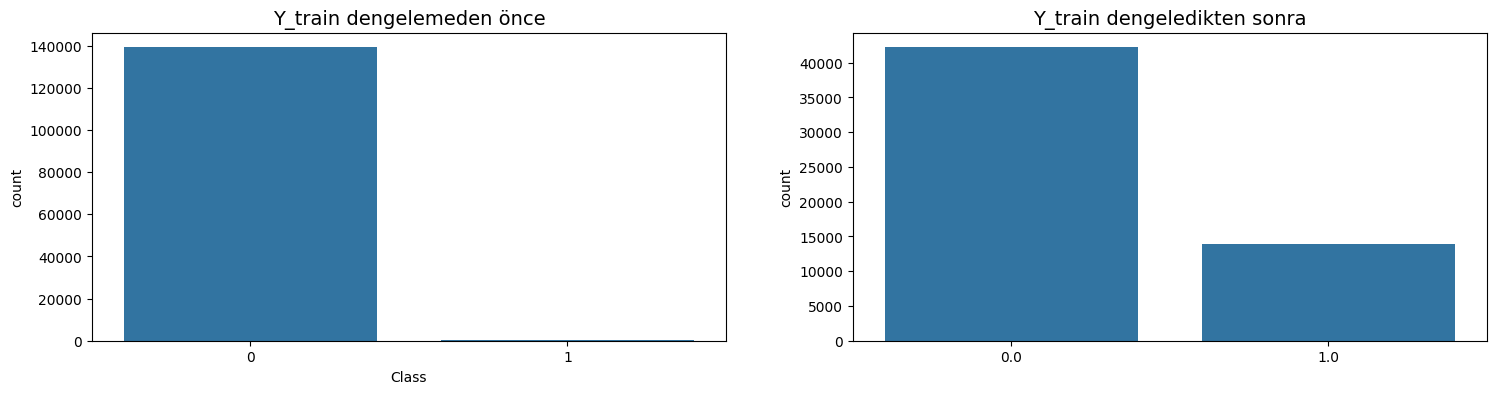

In [36]:
# çizim
warnings.filterwarnings('ignore')
fig, ax = plt.subplots(1, 2, figsize=(18,4))

''' Sınıfları dengelemeden önce'''

sns.countplot(x=y_train, ax=ax[0])
ax[0].set_title('Y_train dengelemeden önce', fontsize=14)

''' Sınıfları dengeledikten sonra'''

sns.countplot(x=y_train_res, ax=ax[1])
ax[1].set_title('Y_train dengeledikten sonra', fontsize=14);

In [37]:
print(X_train_res.shape)
print(X_val.shape)

(56138, 30)
(59810, 30)


## 2. Sinir Ağı yinelemeleri

Sınıflarınızı yeniden dengelediğinize göre, test puanınızı optimize etmek için bir sinir ağı uyarlayın. Aşağıdaki ipuçlarını kullanmaktan çekinmeyin:

- Girişlerinizi normalleştirin!
    - Modelinizdeki ön işlemeyi “boru hattı” haline getirmek için tercihen model içinde bir [`Normalization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Normalization) katmanı kullanın. 
    - Veya modelinizin dışında sklearn'in [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) öğesini kullanın, `X_train`, `X_val` ve `X_test` öğelerini uygulayın.
- Modelinizi aşırı uyumlu hale getirin, ardından aşağıdakileri kullanarak düzenleyin:
- Erken Durdurma kriterleri
- [`Dropout`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout) katmanları
    - veya [`düzenleyiciler`](https://www.tensorflow.org/api_docs/python/tf/keras/regularizers) katmanları
- 🚨 İzlemek istediğiniz metrikleri ve kullanmak istediğiniz kayıp fonksiyonunu dikkatlice düşünün!

In [40]:
metrics = [
    keras.metrics.Recall(name='recall'),
    keras.metrics.Precision(name='precision'),
    keras.metrics.AUC(name='prc', curve='PR'),  # precision-recall curve
]

In [41]:
# SENİN KODUN BURAYA
def init_model():
    normalizer = layers.Normalization()
    normalizer.adapt(X_train_res)
    
    model = models.Sequential()
    
    model.add(normalizer)
    model.add(layers.Dense(32, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(16, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(8, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1, activation='sigmoid'))
    
    optimizer = optimizers.Adam(learning_rate=0.001)
    model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=metrics)
    
    return model

In [42]:
model = init_model()
model.summary

<bound method Model.summary of <Sequential name=sequential_1, built=False>>

In [44]:
es = EarlyStopping(
    patience=10,
    monitor='val_recall', # Dolandırıcılık işlemlerini gerçekten tespit etmek istiyoruz!
    restore_best_weights=True)

history = model.fit(X_train_res, y_train_res,
                    validation_data=(X_val, y_val),
                    epochs=100,
                    batch_size=64, # Dolandırıcılık işlemlerini içerme şansı elde etmek için yeterince büyük
                    callbacks=[es], shuffle=True)

Epoch 1/100
878/878 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - loss: 0.2480 - prc: 0.9162 - precision: 0.8214 - recall: 0.8286 - val_loss: 0.0288 - val_prc: 0.7025 - val_precision: 0.2314 - val_recall: 0.8571
Epoch 2/100
878/878 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.1113 - prc: 0.9763 - precision: 0.9766 - recall: 0.9233 - val_loss: 0.0266 - val_prc: 0.7096 - val_precision: 0.2373 - val_recall: 0.8571
Epoch 3/100
878/878 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0831 - prc: 0.9863 - precision: 0.9795 - recall: 0.9452 - val_loss: 0.0242 - val_prc: 0.6843 - val_precision: 0.2320 - val_recall: 0.8571
Epoch 4/100
878/878 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0709 - prc: 0.9900 - precision: 0.9813 - recall: 0.9539 - val_loss: 0.0164 - val_prc: 0.6796 - val_precision: 0.3217 - val_recall: 0.8469
Epoch 5/100
878/878 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - loss: 0.0589 - prc: 0.9925 - precision: 0.9835 - recall: 0.9622 - val_loss: 0.0172 - val_prc: 0.6743 - val_precision: 0.2795 - val_

In [45]:
def plot_loss_precision_recall_curve(history):

    fig, ax =plt.subplots(1, 3, figsize=(20,5))

    # --- LOSS

    ax[0].plot(history.history['loss'])
    ax[0].plot(history.history['val_loss'])
    ax[0].set_title('Model loss')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Loss')
    ax[0].legend(['Train', 'Val'], loc='upper right')
    ax[0].grid(axis="x", linewidth=0.5)
    ax[0].grid(axis="y", linewidth=0.5)

    # --- RECALL

    ax[1].plot(history.history['recall'])
    ax[1].plot(history.history['val_recall'])
    ax[1].set_title('Model recall', fontsize=18)
    ax[1].set_xlabel('Epoch', fontsize=14)
    ax[1].set_ylabel('Recall', fontsize=14)
    ax[1].legend(['Train', 'Val'], loc='lower right')
    ax[1].grid(axis="x", linewidth=0.5)
    ax[1].grid(axis="y", linewidth=0.5)


    # --- PRECISION


    ax[2].plot(history.history['precision'])
    ax[2].plot(history.history['val_precision'])
    ax[2].set_title('Model precision', fontsize=18)
    ax[2].set_xlabel('Epoch', fontsize=14)
    ax[2].set_ylabel('Precision', fontsize=14)
    ax[2].legend(['Train', 'Val'], loc='lower right')
    ax[2].grid(axis="x", linewidth=0.5)
    ax[2].grid(axis="y", linewidth=0.5)

    plt.show()

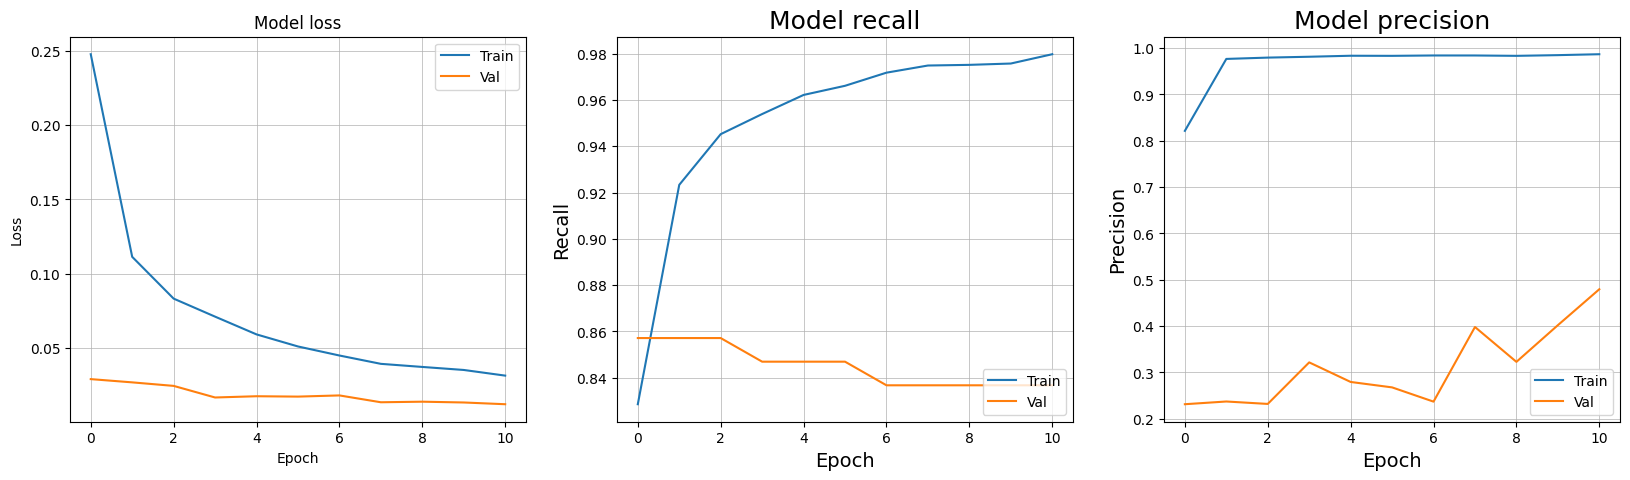

In [46]:
plot_loss_precision_recall_curve(history)

In [47]:
model.evaluate(X_test, y_test, verbose=0, return_dict=True)

{'loss': 0.027695827186107635,
 'prc': 0.7324895262718201,
 'precision': 0.22061483561992645,
 'recall': 0.8970588445663452}

In [48]:
y_pred_proba = model.predict(X_test)

2671/2671 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step


In [49]:
threshold = 0.50 # 50%

y_pred_binary = np.where(y_pred_proba > threshold, 1, 0 )

In [50]:
# Karışıklık Matrisi
cm = confusion_matrix(y_test, y_pred_binary)
cm

array([[84876,   431],
       [   14,   122]])

In [51]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_binary))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     85307
           1       0.22      0.90      0.35       136

    accuracy                           0.99     85443
   macro avg       0.61      0.95      0.68     85443
weighted avg       1.00      0.99      1.00     85443



### 🧪 Kodunu Test Et

Orijinal dengesiz veri kümesinin (`X_test`, `y_test`) temsil edici bir örneğinde gerçek test performansınızın altında kalan sonuçları `precision` ve `recall` değişkenlerine kaydedin.

In [53]:
# SENİN KODUN BURAYA
precision =  0.67
recall = 0.95

In [54]:
from nbresult import ChallengeResult

result = ChallengeResult('solution',
    precision=precision,
    recall=recall,
    fraud_number=len(y_test[y_test == 1]),
    non_fraud_number=len(y_test[y_test == 0]),
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/atabe/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/atabe/code/ata1971
configfile: pyproject.toml
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 2 items

test_solution.py::TestSolution::test_is_score_good_enough PASSED         [ 50%]
test_solution.py::TestSolution::test_is_test_set_representative PASSED   [100%]

============================== 2 passed in 0.13s ===============================


💯 You can commit your code:

git add tests/solution.pickle

git commit -m 'Completed solution step'

git push origin master



## 🏁 İsteğe bağlı: Bu zorluk için Google'ın çözümünü okuyun
Bu oturumdaki tüm zorlukları tamamladığınız için tebrikler!

Son olarak, Google'ın kendi çözümünü doğrudan [Colab'da buradan](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/structured_data/imbalanced_data.ipynb) okuyun. 

İlginç teknikler ve en iyi uygulamaları keşfedeceksiniz.